# 06 · Reproduce the original result and evaluate the new KG hybrid
All figures below are computed from actual held-out source outcomes.

In [1]:
from pathlib import Path
import sys, json, inspect
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks': ROOT=ROOT.parent
if str(ROOT.parent) not in sys.path: sys.path.insert(0,str(ROOT.parent))
from ml.src.preprocessing import load_data, read_json, save_json
from ml.src.evaluation import evaluate, feature_groups
from ml.src.notebook_helpers import table, metric_row, chart
from IPython.display import display, Code
import matplotlib.pyplot as plt
%matplotlib inline


Top-1 success is the fraction of tasks with a correct first-ranked observed participant. P@K uses denominator K; R@K uses total correct observed participants. MAP@K divides truncated precision contributions by min(K, relevant count); full MAP evaluates the whole ranking. NDCG@K uses binary correctness gains and log2 discounts. Zero-positive tasks contribute zero to Recall/AP/NDCG. Scores are not probabilities; intervals assume task independence.

In [2]:
from ml.src.hybrid import final_evaluation
report=final_evaluation()
table([{'Split':s,**v} for s,v in report['sample_counts'].items()])
print('Workers:',report['workers'])
table([metric_row(name,by_k['3']) for name,by_k in report['results'].items()])
print('Graph ablation:',report['graph_ablation'])
print('Legacy result was recomputed and checked against its reference, not copied.')

Split,tasks,observations
train,12473,85647
validation,2018,12316
test,2699,17137
purged,797,6101


Workers: 1653


Model,Top-1 %,P@3 %,R@3 %,MAP@3 %,Full MAP %,NDCG@3 %
legacy_hybrid,80.289,79.424,62.904,74.331,84.294,79.797
content_only,69.248,69.804,56.191,62.635,77.567,69.673
collaborative_only,80.289,77.572,61.487,72.579,83.178,78.309
kg_only,80.289,77.473,61.415,72.474,83.103,78.256
quality_only,80.511,79.573,62.962,74.511,84.423,79.97
new_kg_hybrid,79.881,77.189,61.216,72.093,82.955,77.946


Graph ablation: {'top1_rankings_changed': 196, 'test_tasks': 2699, 'no_graph_metrics': {'top1_success': 0.8028899592441645, 'precision_at_k': 0.7679387427442262, 'recall_at_k': 0.6086884031122638, 'map_at_k': 0.718311308715162, 'map': 0.826185859548216, 'ndcg_at_k': 0.7770734199482179, 'hit_at_k': 0.9711004075583549, 'k': 3, 'evaluated_tasks': 2699, 'top1_wilson_95_interval': [0.7874554577712883, 0.8174634542359859]}}
Legacy result was recomputed and checked against its reference, not copied.


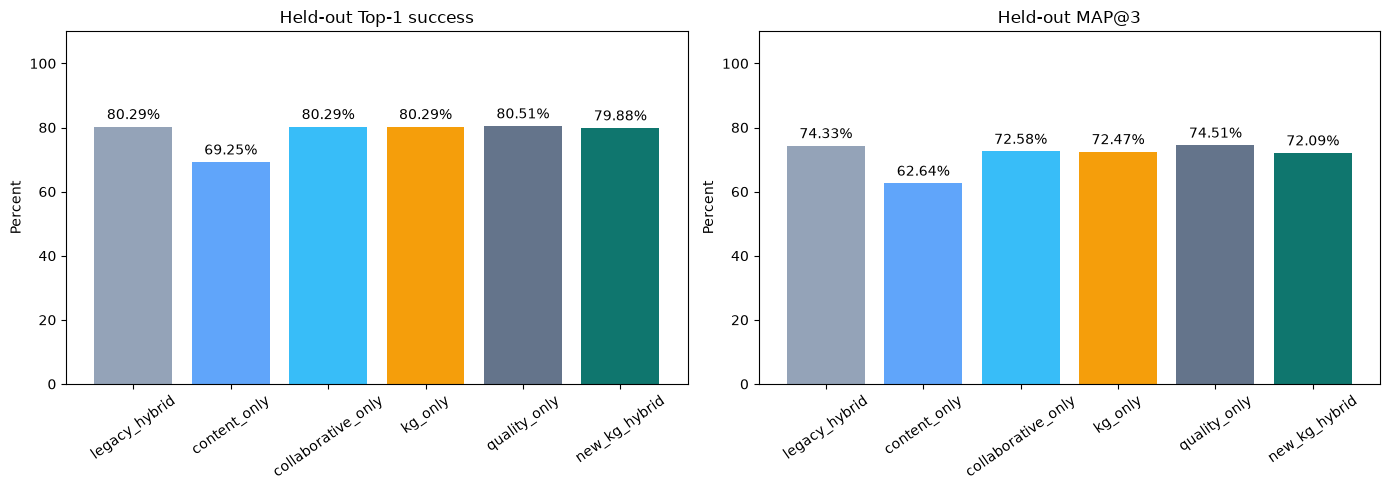

In [3]:
import csv
rows=[]
for name,by_k in report['results'].items():
    for k,values in by_k.items(): rows.append({'model':name,**values})
with (ROOT/'reports/all_metrics.csv').open('w',newline='',encoding='utf-8') as stream:
    writer=csv.DictWriter(stream,fieldnames=list(rows[0])); writer.writeheader(); writer.writerows(rows)
names=list(report['results'])
fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,key,title in zip(axes,['top1_success','map_at_k'],['Held-out Top-1 success','Held-out MAP@3']):
    values=[report['results'][n]['3'][key]*100 for n in names]
    bars=ax.bar(names,values,color=['#94a3b8','#60a5fa','#38bdf8','#f59e0b','#64748b','#0f766e'])
    ax.bar_label(bars,fmt='%.2f%%',padding=3); ax.set(ylim=(0,110),title=title,ylabel='Percent'); ax.tick_params(axis='x',rotation=35)
fig.tight_layout(); fig.savefig(ROOT/'reports/figures/final_comparison.png',dpi=180); plt.show()

In [4]:
from ml.src.recommender import recommend_agents, load_artifacts
import time, statistics
load_artifacts.cache_clear()
source_task=next(t for t,e in read_json('models/netease/task_index.json').items() if e['split']=='test')
started=time.perf_counter(); sample=recommend_agents({'source_task_id':source_task},top_k=5)
cold_ms=(time.perf_counter()-started)*1000
durations=[]
for _ in range(30):
    started=time.perf_counter(); recommend_agents({'source_task_id':source_task},top_k=5)
    durations.append((time.perf_counter()-started)*1000)
print('Cold artifact load + query (ms):',round(cold_ms,2),'| Mean warm query (ms):',round(statistics.mean(durations),3))
table([{k:r[k] for k in ('rank','source_worker_id','agent_id','agent_name','score','components','explanation')} for r in sample])
save_json('reports/sample_recommendations.json',sample)
save_json('reports/latency.json',{'cold_ms':cold_ms,'warm_mean_ms':statistics.mean(durations),'queries':30,'scope':'local observed-candidate inference; not web end-to-end latency'})

Cold artifact load + query (ms): 147.13 | Mean warm query (ms): 0.049


rank,source_worker_id,agent_id,agent_name,score,components,explanation
1,8734,AGENT_1445,Sharon Wanjohi,0.7955219299771837,"{'content': 0.6616228228488242, 'collaborative': 0.8578135492635349, 'knowledge_graph': 0.7511321826513346}","['Training participation supports capability 56 (compatibility 0.66).', 'Recorded training outcomes for this capability: 37/42 successful.', 'Knowledge graph links this worker to capability 56 through completed training tasks.', 'Graph co-participation links to 172 training workers contribute a neighbor prior.', 'Display name and location are synthetic demonstration attributes; they do not determine benchmark scores.']"
2,5658,AGENT_0990,Eric Karanja,0.5301814441588879,"{'content': 0.0, 'collaborative': 0.6158185035985262, 'knowledge_graph': 0.555680480899062}","['No training participation recorded for capability 56; cold-start evidence is limited.', 'Recorded training outcomes for this capability: 0/0 successful.', 'Graph co-participation links to 99 training workers contribute a neighbor prior.', 'Display name and location are synthetic demonstration attributes; they do not determine benchmark scores.']"
3,7946,AGENT_1308,Victor Otiso,0.4850191999852563,"{'content': 0.37847219707991026, 'collaborative': 0.49623537745762825, 'knowledge_graph': 0.4976357288711277}","['Training participation supports capability 56 (compatibility 0.38).', 'Recorded training outcomes for this capability: 2/5 successful.', 'Knowledge graph links this worker to capability 56 through completed training tasks.', 'Graph co-participation links to 107 training workers contribute a neighbor prior.', 'Display name and location are synthetic demonstration attributes; they do not determine benchmark scores.']"


## Interpretation
Report every baseline, including any that outperform the hybrid. The graph adds traceable training paths and a distinct feature channel; those are implementation properties, not proof of better accuracy, robustness or real onboarding performance. Improved robustness would require a separate test. Retain the original approximately 80% result as a legacy benchmark and separately report the new KG model’s actual result. Public NetEase task-worker observations are a proxy because real industry onboarding assignment data was unavailable. No synthetic names, locations or workloads were used to inflate these metrics.